# 

# Example of the aitlas toolbox in the context of object detection

## Import the required packages

In [ ]:
from aitlas.datasets import OIRDSDataset
from aitlas.models import FasterRCNN
from aitlas.transforms import Resize
from aitlas.utils import image_loader

## Load the dataset

In [5]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
}
dataset = OIRDSDataset(dataset_config)
print(len(dataset))

908


## Show images from the dataset

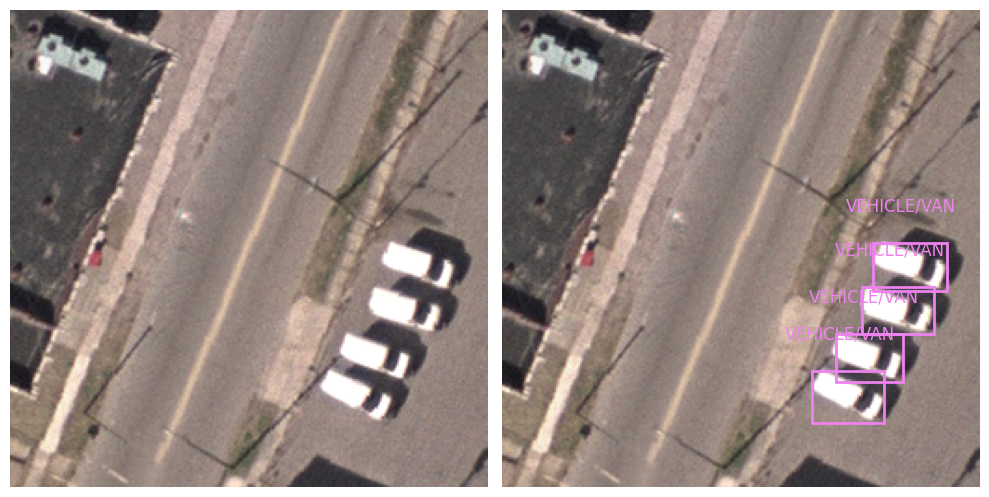

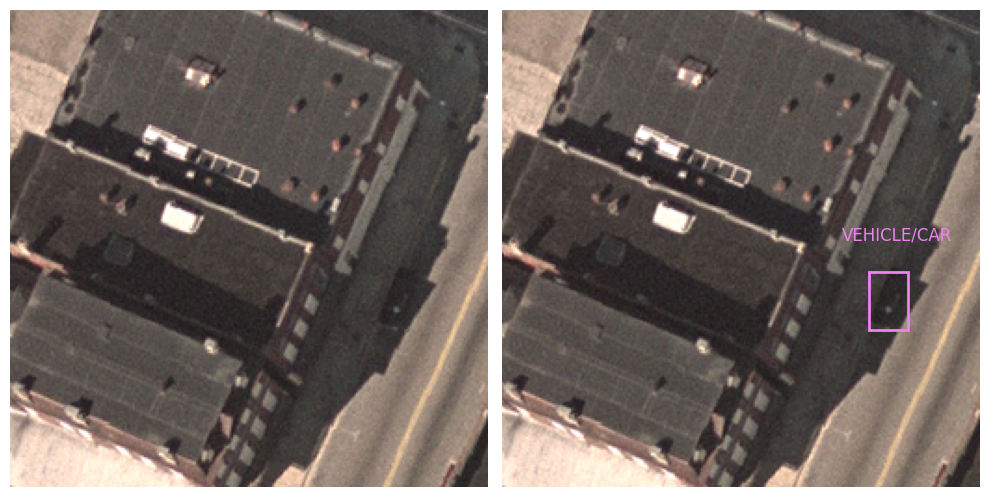

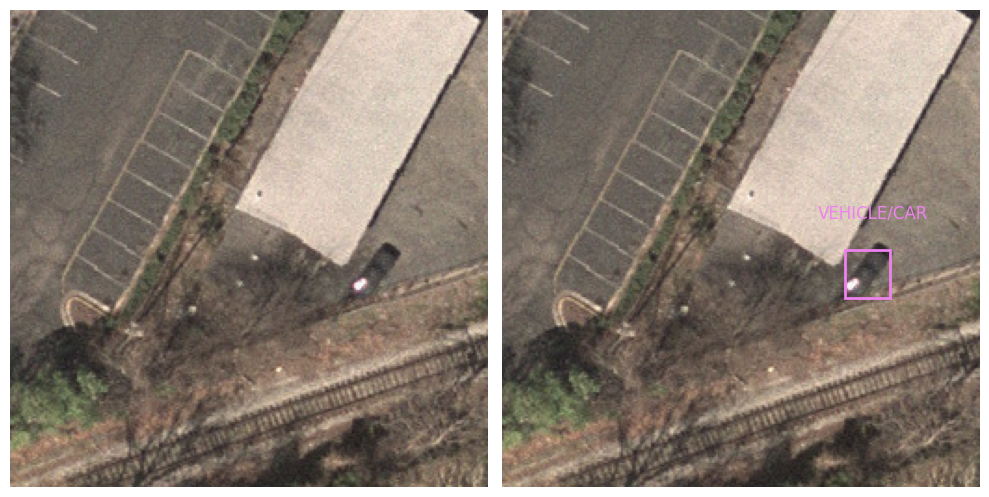

In [6]:
fig1 = dataset.show_image(1)
fig2 = dataset.show_image(2)
fig3 = dataset.show_image(3)

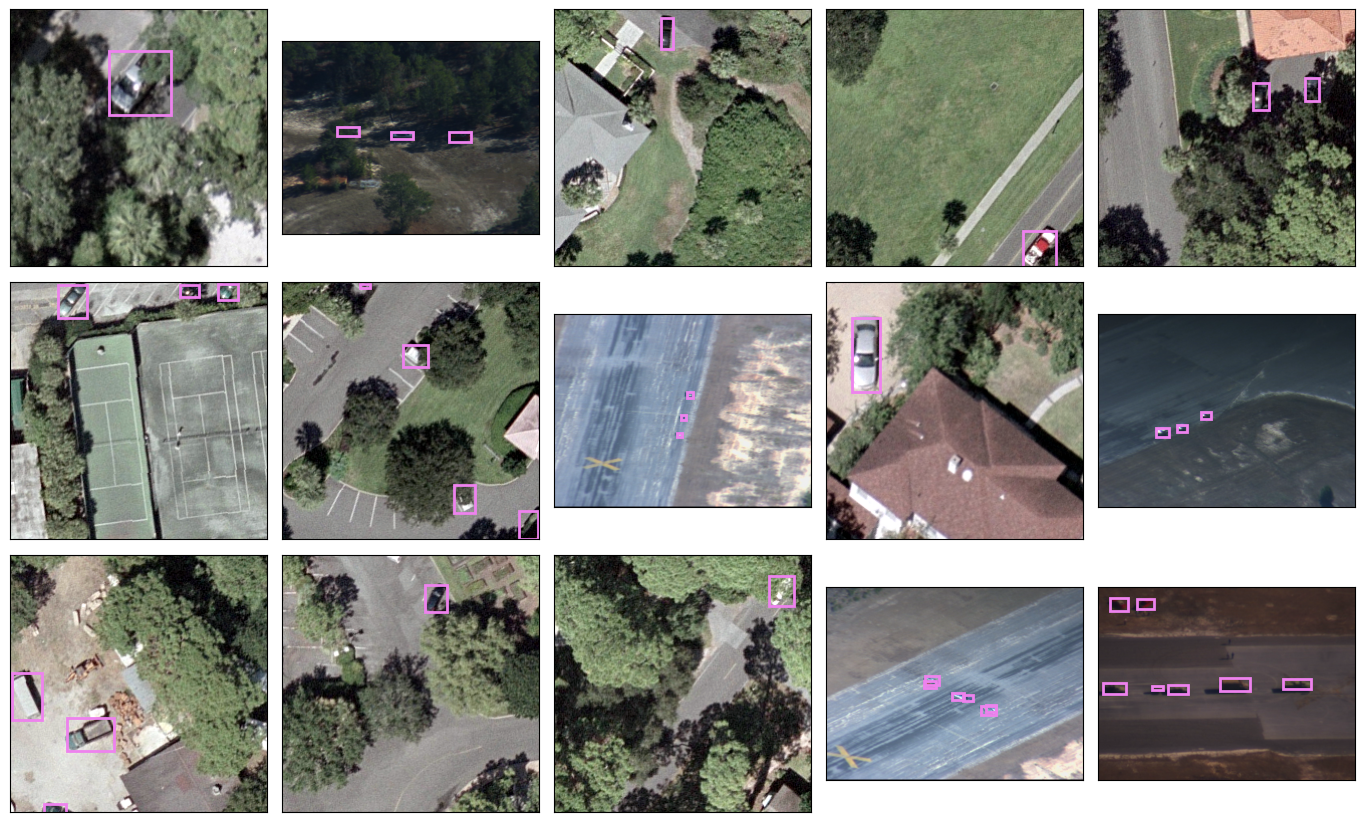

In [4]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [111]:
dataset.data_distribution_table()

,Label,Count
0,VEHICLE/CAR,1020
1,VEHICLE/PICK-UP,352
2,VEHICLE/UNKNOWN,172
3,VEHICLE/VAN,156
4,VEHICLE/TRUCK,96


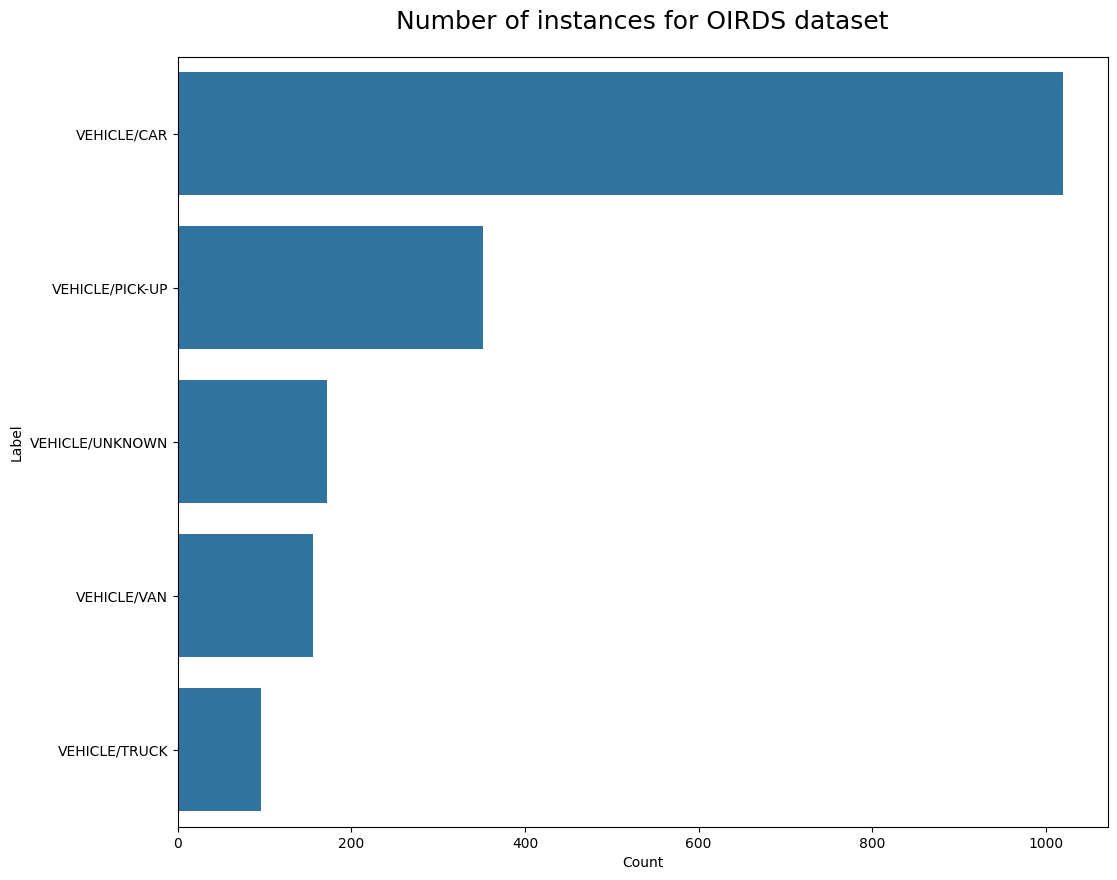

In [112]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [5]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "csv_file": "/home/dragik/data/FAIR_EO/OIRDS/oirds_train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = OIRDSDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 544


## Setup and create the model for training

In [8]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/oirds/"
model_config = {
    "num_classes": 6,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Training and validation

In [9]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2026-01-12 13:47:58,706 INFO Starting training.
training: 100%|██████████| 68/68 [00:23<00:00,  2.88it/s]
2026-01-12 13:48:22,363 INFO epoch: 1, time: 24, loss:  0.38645
testing on train set: 100%|██████████| 68/68 [00:13<00:00,  5.01it/s]
2026-01-12 13:48:38,092 INFO map:0.10606851428747177, map_50:0.1701316237449646, map_75:0.13127928972244263, map_small:0.07397924363613129, map_medium:0.10816419869661331, map_large:0.7626237869262695, mar_1:0.08501861244440079, mar_10:0.1355256587266922, mar_100:0.1355256587266922, mar_small:0.11621621251106262, mar_medium:0.13677996397018433, mar_large:0.7749999761581421, map_per_class:tensor(0.5232), tensor(0.0071), tensor(0.), tensor(0.), tensor(0.), mar_100_per_class:tensor(0.6705), tensor(0.0071), tensor(0.), tensor(0.), tensor(0.), classes:tensor(1, dtype=torch.int32), tensor(2, dtype=torch.int32), tensor(3, dtype=torch.int32), tensor(4, dtype=torch.int32), tensor(5, dtype=torch.int32)
training: 100%|██████████| 68/68 [00:23<00:00,  2.87it/s]


## Evaluate the model

In [10]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "annotation_dir": "/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/",
    "csv_file": "/home/dragik/data/FAIR_EO/OIRDS/oirds_val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = OIRDSDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 182


2026-01-12 13:54:31,554 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar
2026-01-12 13:54:31,912 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 23/23 [00:05<00:00,  4.29it/s]


[{'map': 0.2705177664756775,
  'map_50': 0.3923666775226593,
  'map_75': 0.3390358090400696,
  'map_small': 0.07284149527549744,
  'map_medium': 0.2824266850948334,
  'map_large': 0.0,
  'mar_1': 0.2775565981864929,
  'mar_10': 0.35602685809135437,
  'mar_100': 0.35602685809135437,
  'mar_small': 0.127692312002182,
  'mar_medium': 0.36072543263435364,
  'mar_large': 0.0,
  'map_per_class': [tensor(0.4805),
   tensor(0.3977),
   tensor(0.0139),
   tensor(0.3671),
   tensor(0.0934)],
  'mar_100_per_class': [tensor(0.5624),
   tensor(0.5205),
   tensor(0.1031),
   tensor(0.4774),
   tensor(0.1167)],
  'classes': [tensor(1, dtype=torch.int32),
   tensor(2, dtype=torch.int32),
   tensor(3, dtype=torch.int32),
   tensor(4, dtype=torch.int32),
   tensor(5, dtype=torch.int32)]}]

## Predictions

2026-01-12 13:54:45,507 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar
2026-01-12 13:54:45,873 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar at epoch 11


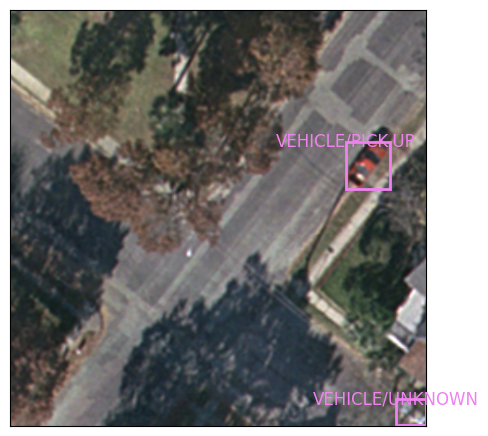

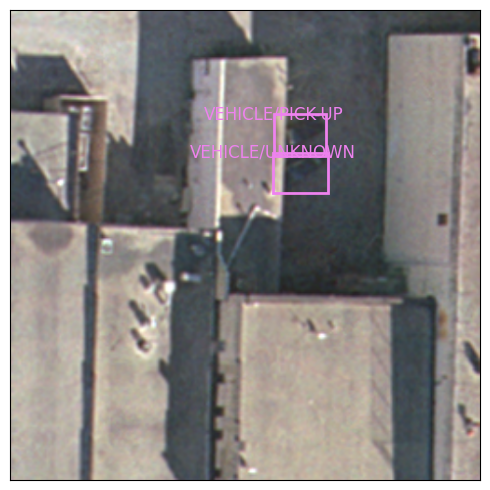

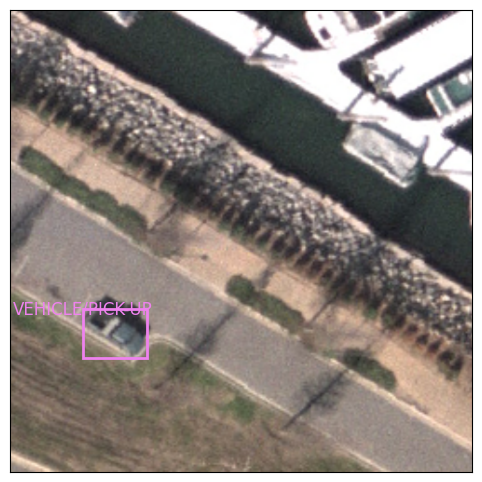

In [11]:
model_config = {
    "num_classes": 6,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/oirds/checkpoint.pth.tar"
labels = ["no-data","VEHICLE/CAR", "VEHICLE/PICK-UP", "VEHICLE/UNKNOWN", "VEHICLE/VAN", "VEHICLE/TRUCK"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/DataSet_19/51764373_1025_6657_1281_6913.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/DataSet_19/61407638_1281_3329_1537_3585.tif')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/OIRDS/OIRDS_v1_0/DataSet_20/33245545_1537_2305_1793_2561.tif')
fig = model.detect_objects(image, labels, transform)